### Imports and Setup

In [1]:
# For Configuration File
import yaml
from pathlib import Path
import importlib
from obspy import UTCDateTime as UTC
import csv
import numpy as np
import matplotlib.pyplot as plt
from obspy import Stream
import pickle

config_path = 'C:\\Users\\SkyFish\\Desktop\\Honours\\seismic-weather\\config.yaml'

# Load Config File
with open(config_path, "r") as f:
    config = yaml.safe_load(f)

# Config Variables
name = config["name"]
seismic_path = config["seismic_data_path"]
seismic_data = Path(config['seismic_data_path'])
aws_path = config['aws_dir']
seiswind_module = config['seiswind_module']

# obspy GitHub:
# https://github.com/obspy/obspy
from obspy import UTCDateTime as UTC

# seismic-weather GitHub:
# https://github.com/Ramirezs873/seismic-weather
spec = importlib.util.spec_from_file_location("seismicwind", seiswind_module)
seismicwind = importlib.util.module_from_spec(spec)
spec.loader.exec_module(seismicwind)

In [2]:
# Load class Seismic
## Load with config file
seis = seismicwind.Seismic(config=config)

### Download and Process Each Day of Data

In [ ]:
# Station Info
# Stat  Name        Lat     Lon         Start       End
'CWA86	Near Skiway	-66.278	110.7753	2022-01-21	2023-11-25'

# Initial Variables
t_i = UTC(2022, 1, 22, 0, 0)
t_e = UTC(2022, 1, 23, 0, 0)
i = 0

# Excluded dates
ex_dates = []

# Iterate through amount of days available
for num in range(673): 

    # Times + 0 initially, then an extra day for each subsequent iteration
    t_start = t_i + i
    t_end = t_e + i

    # Gather seismic data but only store as a variable to save space
    stat = seis.get_seis(client = 'AUSPASS',
                network = 'Z9',
                station = 'CWA86',
                location = '*',
                channel = '*',
                t_start = t_start,
                t_end = t_end,
                username = 'Z9',
                password = 'peach25',
                file_name = f'test',
                save = False)

    # Check if the date has discontinuities in the time series, contains NaNs, or inconsitent recording times
    # This is known if there are more than 3 traces in the stream
    # Preprocessing breaks if the data contains NaNs
    # So we dont want to save it
    if (not seis.st 
        or len(seis.st['Z9.CWA86.']) != 3 
        or any(np.isnan(seis.st['Z9.CWA86.'][0].data)) 
        or len(stat.st['Z9.CWA86.'][0].data) != len(stat.st['Z9.CWA86.'][1].data) != len(stat.st['Z9.CWA86.'][2].data)):

        print(f"Skipping {t_start.strftime('%Y-%m-%d')}: NaNs or no data")

        # Store the excluded date for further investigation
        ex_dates.append(t_start.strftime('%Y-%m-%d'))

        # Go to the next day
        i = i + 86400

        continue

    # Orientation Correction
    seis.preprocess.rotate(NS_channel = ['HHN'], EW_channel = ['HHE'], Z_channel = ['HHZ'],
                misalignment_angle = [-5.74])
    
    # Demean
    seis.preprocess.demean()

    # Detrend
    seis.preprocess.detrend()

    # Hann Window
    seis.preprocess.window(max_length = 100, save_mseed = True, file_name = f'{t_start.strftime("%Y-%m-%d")}_CWA86_pp')

    # Go to the next day
    i = i + 86400
    

### Inspect AWS Timespans

In [ ]:
aws = seis.wind.get_aws(path=aws_path,
                    station_code = 300060,
                    id_code = 55510926053)

In [ ]:
WS = seis.wind.get_var(variable='Wind speed in km/h',
                   t_start=UTC(2023, 11, 1),
                    t_end=UTC(2023, 12, 20))
seis.wind.plot_aws()

### Establish Taining and Predicting Periods

In [3]:
# Training Period Dates 
# AWS Casey Skiway South aligned with CWA86

# Section 1
t1_start =  UTC(2022, 1, 22)
t1_end = UTC(2022, 2, 18)

# Section 2
t2_start =  UTC(2022, 11, 21)
t2_end = UTC(2022, 12, 18)

# Section 3
t3_start = UTC(2022, 12, 20)
t3_end = UTC(2023, 1, 5)

# Section 4
t4_start = UTC(2023, 1, 7)
t4_end = UTC(2023, 1, 29)

# Section 5
t5_start = UTC(2023, 1, 31)
t5_end = UTC(2023, 2, 17)

# Section 6
t6_start =  UTC(2023, 11, 2)
t6_end = UTC(2023, 11, 24)



# Predicting Periods Dates
# Only CWA86
# These are two massive periods. 
# Writing crashes for extremely large files so split up


# Section 1a 
p1a_start = UTC(2022, 2, 19)
p1a_end = UTC(2022, 3, 15)

# Section 1b
p1b_start = UTC(2022, 3, 16)
p1b_end = UTC(2022, 4, 15)

# Section 1c
p1c_start = UTC(2022, 4, 16)
p1c_end = UTC(2022, 5, 15)

# Section 1d
p1d_start = UTC(2022, 5, 16)
p1d_end = UTC(2022, 6, 10)

# Section 1e
p1e_start = UTC(2022, 6, 11)
p1e_end = UTC(2022, 7, 10)

# Section 1f
p1f_start = UTC(2022, 7, 11)
p1f_end = UTC(2022, 7, 31)

# Section 1g
p1g_start = UTC(2022, 8, 2)
p1g_end = UTC(2022, 8, 31) 

# Section 1h
p1h_start = UTC(2022, 9, 1)
p1h_end = UTC(2022, 9, 30) 

# Section 1i
p1ia_start = UTC(2022, 10, 1)
p1ia_end = UTC(2022, 10, 14) 

p1ib_start = UTC(2022, 10, 15)
p1ib_end = UTC(2022, 11, 1)

# Section 1j
p1j_start = UTC(2022, 11, 2)
p1j_end = UTC(2022, 11, 20) 




# Section 2a
p2a_start = UTC(2023, 2, 18)
p2a_end = UTC(2023, 3, 15)

# Section 2b
p2b_start = UTC(2023, 3, 16)
p2b_end = UTC(2023, 4, 15)

# Section 2c
p2c_start = UTC(2023, 4, 16)
p2c_end = UTC(2023, 5, 15)

# Section 2d
p2d_start = UTC(2023, 5, 16)
p2d_end = UTC(2023, 6, 10)

# Section 2e
p2e_start = UTC(2023, 6, 11)
p2e_end = UTC(2023, 7, 10)

# Section 2f
p2f_start = UTC(2023, 7, 11)
p2f_end = UTC(2023, 7, 31)

# Section 2g
p2g_start = UTC(2023, 8, 2)
p2g_end = UTC(2023, 8, 31) 

# Section 2h
p2h_start = UTC(2023, 9, 1)
p2h_end = UTC(2023, 9, 30) 

# Section 2i
p2i_start = UTC(2023, 10, 1)
p2i_end = UTC(2023, 10, 15) 

# Section 2j
p2j_start = UTC(2023, 10, 16)
p2j_end = UTC(2023, 11, 1) 



train = {
    'train1': (t1_start, t1_end),
    'train2': (t2_start, t2_end),
    'train3': (t3_start, t3_end),
    'train4': (t4_start, t4_end),
    'train5': (t5_start, t5_end),
    'train6': (t6_start, t6_end),}

pred = {
    'predict1a': (p1a_start, p1a_end),
    'predict1b': (p1b_start, p1b_end),
    'predict1c': (p1c_start, p1c_end),
    'predict1d': (p1d_start, p1d_end),
    'predict1e': (p1e_start, p1e_end),
    'predict1f': (p1f_start, p1f_end),
    'predict1g': (p1g_start, p1g_end),
    'predict1h': (p1h_start, p1h_end),
    'predict1ia': (p1ia_start, p1ia_end),
    'predict1ib': (p1ib_start, p1ib_end),
    'predict1j': (p1j_start, p1j_end),

    'predict2a': (p2a_start, p2a_end),
    'predict2b': (p2b_start, p2b_end),
    'predict2c': (p2c_start, p2c_end),
    'predict2d': (p2d_start, p2d_end),
    'predict2e': (p2e_start, p2e_end),
    'predict2f': (p2f_start, p2f_end),
    'predict2g': (p2g_start, p2g_end),
    'predict2h': (p2h_start, p2h_end),
    'predict2i': (p2i_start, p2i_end), 
    'predict2j': (p2j_start, p2j_end),
    }

### Merge the Days into the Larger Sections

#### Sometimes this step stuffs up and merges silently fail. e.g. NS and EW merge correctly, but Z does not

In [ ]:
# Load and merge each section, be careful with large time periods
train = {
    'train1': (p1ia_start, p1ia_end),
    'train2': (p1ib_start, p1ib_end),}
for sec, (t_start, t_end) in train.items():

    stream = Stream()

    t_i = UTC(t_start.year, t_start.month, t_start.day)
    t_e = UTC(t_end.year, t_end.month, t_end.day)

    while t_i <= t_e:
    
        stat = seis.get_seis(client=None,
                                network=None,
                                station=None,
                                location=None,
                                channel=None,
                                t_start=None,
                                t_end=None,
                                username=None,
                                password=None,
                                file_name=f'{t_i.strftime("%Y-%m-%d")}_CWA86_pp',
                                save=False).st

        if stat:
            stream += Stream(stat['Z9.CWA86.'])

        else:
            print(f'No data: {t_i.strftime("%Y-%m-%d")}')


        t_i += 86400

    stream.merge(method=0, fill_value=None)
    stream.write(seismic_data/f'pred_{t_start.strftime("%Y-%m-%d")}_to_{t_end.strftime("%Y-%m-%d")}.mseed',format='MSEED')

    print(f'{sec} merged and saved')

### Apply FFT to the Training Periods

In [ ]:
# for 6 training periods.
# You may need to split this up to avoid memory issues also
train = {
    #'train1': (t1_start, t1_end),
    #'train2': (t2_start, t2_end),
    #'train3': (t3_start, t3_end),
    'train4': (t4_start, t4_end),
    'train5': (t5_start, t5_end),
    'train6': (t6_start, t6_end),}

fft_train = []

for i in range(3): # 6 
    start = train[f'train{i+4}'][0] # 1
    end = train[f'train{i+4}'][1] # 1
    
    stat = seis.get_seis(client = None,
                        network = None,
                        station = None,
                        location = None,
                        channel = None,
                        t_start = None,
                        t_end = None,
                        username = None,
                        password = None,
                        file_name = f'{start.strftime("%Y-%m-%d")}_to_{end.strftime("%Y-%m-%d")}_CWA86_pp')
                        
    WS = seis.wind.get_var(variable='Wind speed in km/h',
                            t_start=UTC(start) + 60*30, # + 30 mins to align times
                            t_end=UTC(end)) 


    fft_train.append(seis.wind.seismic_wind.spectra_fft())
    

### Combine FFTs

In [ ]:
fft_combined = {}

for fft in fft_train:

    for station_dict in fft:

        for station, spectra_list in station_dict.items():

            if station not in fft_combined:
                fft_combined[station] = spectra_list[0].copy()

            else:
                for key in ['EW', 'NS', 'Z', 'time', 'aws_values', 'wind_direction']:

                    fft_combined[station][key] = np.concatenate((fft_combined[station][key],spectra_list[0][key]),axis=0)

In [ ]:
with open(seismic_data / 'fft_combined.pkl', 'wb') as f:
    pickle.dump(fft_combined, f)

#### If multiple fft lists need to be combined. Save all, reload, then combine, and save again
#### Memory issues may be common. Skip following code if there are no issues

In [ ]:
with open(seismic_data / 'fft_train_combined.pkl', 'rb') as f:
    fft_combined1 = pickle.load(f)
with open(seismic_data / 'fft_train2_combined.pkl', 'rb') as f:
    fft_combined = pickle.load(f)

In [ ]:
fft_all = {}

for station in fft_combined:

    fft_all[station] = fft_combined[station].copy()

    for key in ['EW', 'NS', 'Z','time',
                'aws_values', 'wind_direction']:

        fft_all[station][key] = np.concatenate(
            (fft_combined[station][key],
             fft_combined1[station][key]),
            axis=0
        )

In [ ]:
with open(seismic_data / 'fft_train_all_combined.pkl', 'wb') as f:
    pickle.dump(fft_all, f)

### Finally, the model can be trained

In [ ]:
with open(seismic_data / 'fft_train_all_combined.pkl', 'rb') as f:
    fft_combined = pickle.load(f)

#### Optimise
#### This will take a loooooong time

In [ ]:
optimise = seis.wind.seismic_wind.models.optimise_SVR(fmin = 1,
                                                fmax = 49,
                                                f_band_width = 1,
                                                step_size = 1,
                                                n_splits = 10,
                                                min_WS = 3,
                                                WS_only = False,
                                                spectra = fft_combined)

#### Get Model

Entire Week CWA86 optimal WS Parameters

C: 129.15496650148853

gamma: 0.005994842503189409

epsilon: 0.26071428571428573

CV R²: 0.9341924908600046

In [ ]:
svr = seis.wind.seismic_wind.models.SVR(fmin = 1,
                                    fmax = 49,
                                    f_band_width = 1,
                                    step_size = 1,
                                    n_repeats = 15,
                                    min_WS = 3,
                                    poly_degree = 2,
                                    plot_stat_results = False,
                                    plot_results = False,
                                    plot_residuals = False,
                                    plot_power_aws = False,
                                    variable_name = 'AWS Wind Speed (km/hr)',
                                    save_models = True,
                                    file_label = 'full_training_period_CWA86',
                                    spectra = fft_combined,
                                    C = 129.15496650148853,
                                    gamma = 0.005994842503189409,
                                    epsilon = 0.26071428571428573,
                                    C_SVR_WD = 129.15496650148853, # not optimised for WD
                                    gamma_SVR_WD = 0.005994842503189409,
                                    epsilon_SVR_WD = 0.26071428571428573,)

### Apply FFT to the Predicting Periods

In [4]:

# You may need to split this up to avoid memory issues also
pred1a = {
    'predict1a': (p1a_start, p1a_end),
    'predict1b': (p1b_start, p1b_end),
    'predict1c': (p1c_start, p1c_end),
    'predict1d': (p1d_start, p1d_end),}
pred1b = {
    #'predict1e': (p1e_start, p1e_end),
    #'predict1f': (p1f_start, p1f_end),
    #'predict1g': (p1g_start, p1g_end),
    #'predict1h': (p1h_start, p1h_end),
    #'predict1ia': (p1ia_start, p1ia_end),
    #'predict1ib': (p1ib_start, p1ib_end),
    'predict1j': (p1j_start, p1j_end),}
pred2 ={
    'predict2a': (p2a_start, p2a_end),
    'predict2b': (p2b_start, p2b_end),
    'predict2c': (p2c_start, p2c_end),
    'predict2d': (p2d_start, p2d_end),
    'predict2e': (p2e_start, p2e_end),
    'predict2f': (p2f_start, p2f_end),
    'predict2g': (p2g_start, p2g_end),
    'predict2h': (p2h_start, p2h_end),
    'predict2i': (p2i_start, p2i_end), 
    'predict2j': (p2j_start, p2j_end),
    }

fft_train = []

for name, (start, end) in pred1b.items():
  
    stat = seis.get_seis(client = None,
                        network = None,
                        station = None,
                        location = None,
                        channel = None,
                        t_start = None,
                        t_end = None,
                        username = None,
                        password = None,
                        file_name = f'pred_{start.strftime("%Y-%m-%d")}_to_{end.strftime("%Y-%m-%d")}')
                        

    fft_train.append(seis.wind.seismic_wind.no_aws_spectra_fft())
    

Reading existing file: I:\Data\Seismic\pred_2022-11-02_to_2022-11-20.mseed


c:\Users\SkyFish\anaconda3\Lib\site-packages\obspy\io\mseed\core.py:595: UserWarning: In large file mode
  warnings.warn("In large file mode")


### Combine FFTs

In [10]:
fft_combined = {}

for fft in fft_train:

    for station_dict in fft:

        for station, spectra_list in station_dict.items():

            if station not in fft_combined:
                fft_combined[station] = spectra_list[0].copy()

            else:
                for key in ['EW', 'NS', 'Z', 'times',]:

                    fft_combined[station][key] = np.concatenate((fft_combined[station][key],spectra_list[0][key]),axis=0)

In [15]:
with open(seismic_data / 'fft_pred1ba_combined.pkl', 'rb') as f:
    test1 = pickle.load(f)

In [12]:
with open(seismic_data / 'fft_test_combined.pkl', 'wb') as f:
    pickle.dump(fft_train, f)

#### If multiple fft lists need to be combined. Save all, reload, then combine, and save again
#### Memory issues may be common. Skip following code if there are no issues

In [ ]:
with open(seismic_data / 'fft_pred1a_combined.pkl', 'rb') as f:
    fft_combined1 = pickle.load(f)
with open(seismic_data / 'fft_pred1b_combined.pkl', 'rb') as f:
    fft_combined = pickle.load(f)

In [ ]:
fft_all = {}

for station in fft_combined:

    fft_all[station] = fft_combined[station].copy()

    for key in ['EW', 'NS', 'Z','times']:

        fft_all[station][key] = np.concatenate(
            (fft_combined[station][key],
             fft_combined1[station][key]),
            axis=0
        )

In [ ]:
with open(seismic_data / 'fft_pred1_all_combined.pkl', 'wb') as f:
    pickle.dump(fft_all, f)

### Predict!

### Load relevent fft file

In [3]:
with open(seismic_data / 'fft_pred1a_combined.pkl', 'rb') as f: # Feb 2 to June 10
    fft_combined1 = pickle.load(f)

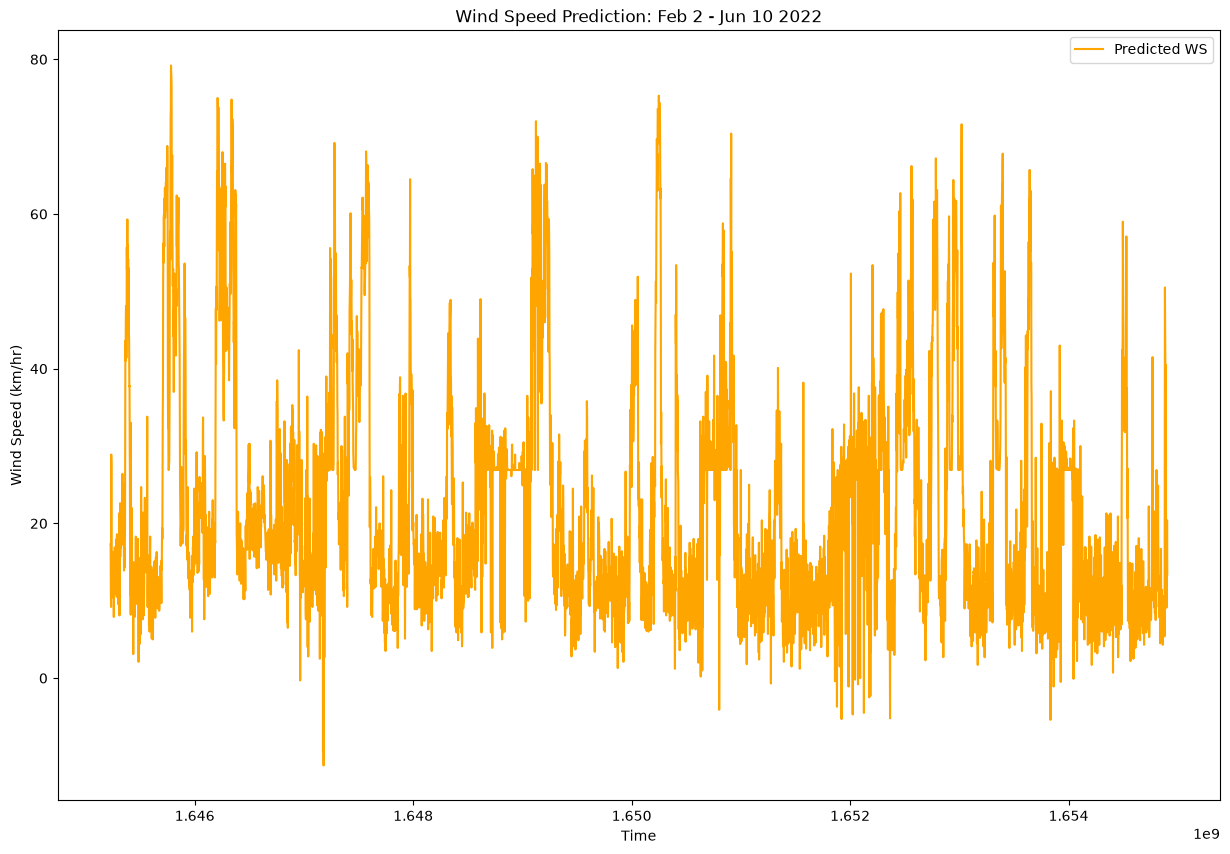

In [4]:
predict1a = seis.wind.seismic_wind.models.no_aws_predict_model(model_path= 'I:\\Data\\Seismic\\SVR_Z9.CWA86._full_training_period_CWA86.joblib',
                                            model_choice = 'SVR',
                                            spectra = fft_combined1,
                                            date = 'Feb 2 - Jun 10 2022',
                                            fig_size = (15,10))

### If multiple large fft files were unable to be loaded. Then Predict on the smaller files and then combine the outputs of the prediction

In [5]:
with open(seismic_data / 'fft_pred1ba_combined.pkl', 'rb') as f: # Jun 11 to Nov 20 2022
    fft_combined2 = pickle.load(f)

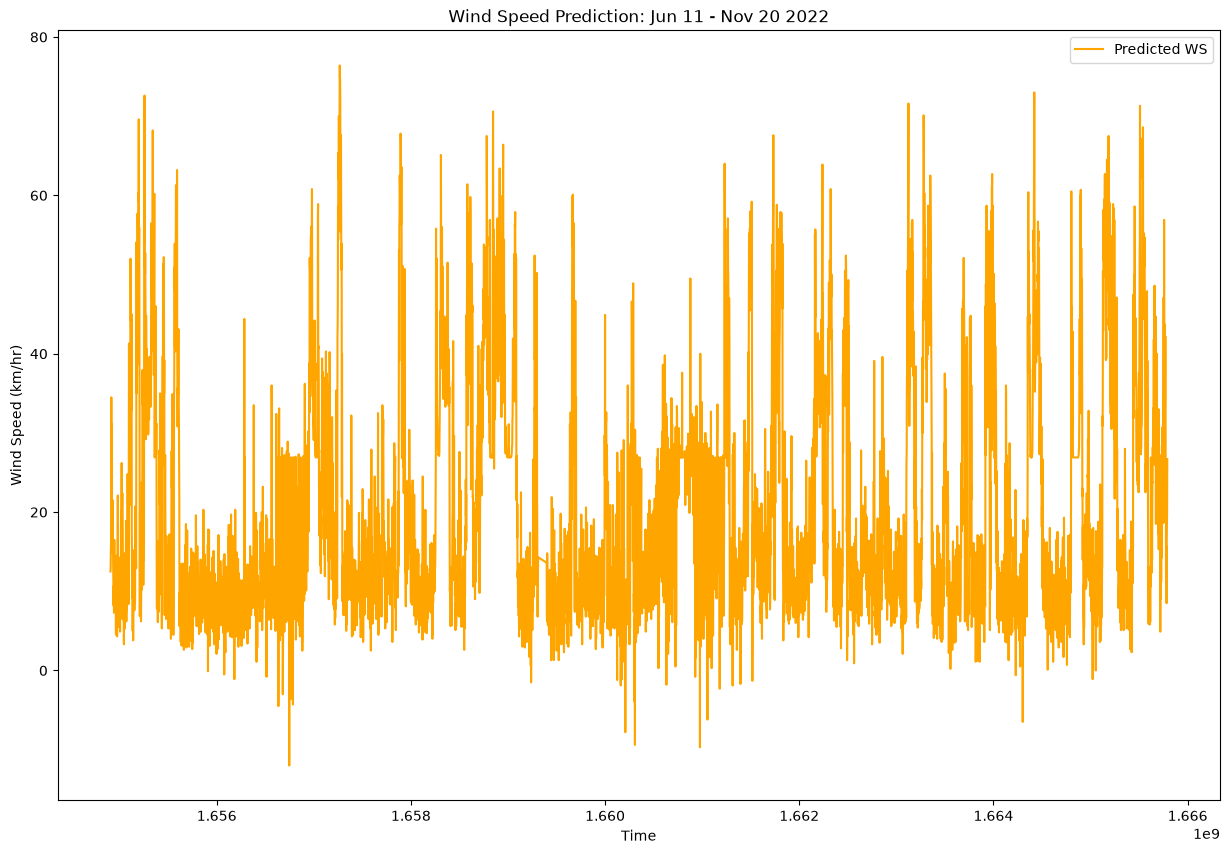

In [6]:
predict1b = seis.wind.seismic_wind.models.no_aws_predict_model(model_path= 'I:\\Data\\Seismic\\SVR_Z9.CWA86._full_training_period_CWA86.joblib',
                                            model_choice = 'SVR',
                                            spectra = fft_combined2,
                                            date = 'Jun 11 - Nov 20 2022',
                                            fig_size = (15,10))

### Combine

In [7]:
ws1a = predict1a['Z9.CWA86.']['Predicted_WS']
ws1b = predict1b['Z9.CWA86.']['Predicted_WS']
times1a = predict1a['Z9.CWA86.']['times']
times1b = predict1b['Z9.CWA86.']['times']


In [8]:
ws1 = np.concatenate((ws1a, ws1b))  
t1 = np.concatenate((times1a, times1b))  

In [9]:
times1 = [t.datetime for t in t1]

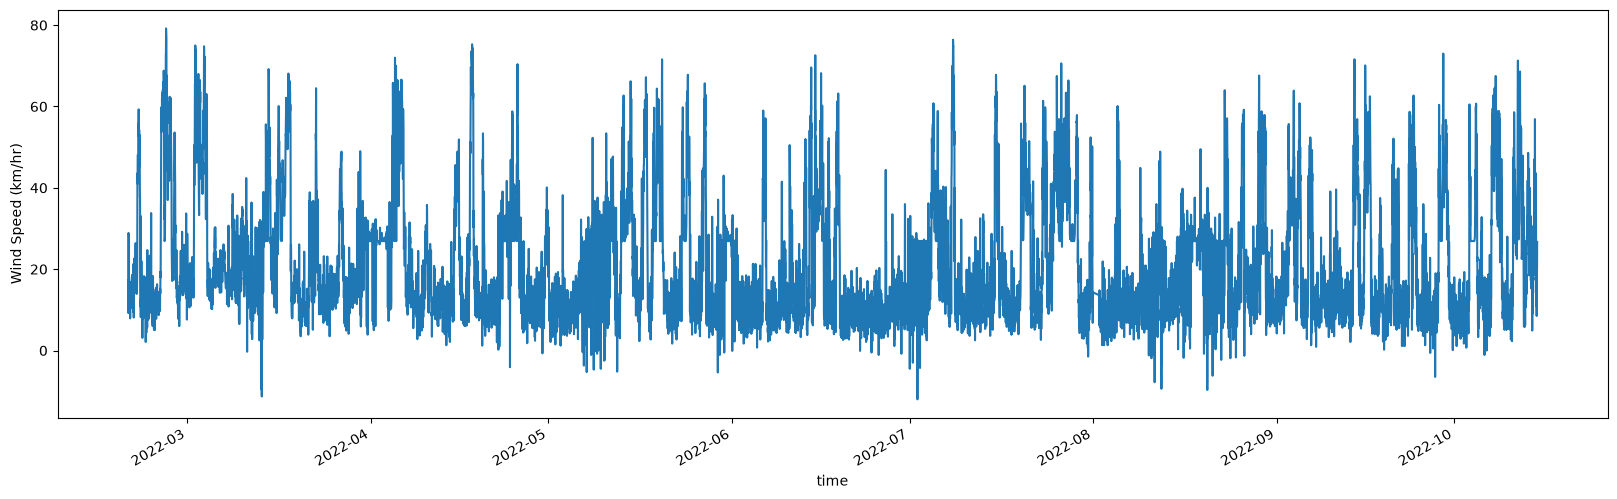

In [10]:
plt.figure(figsize = (20,6))
plt.plot(times1, ws1)
plt.xlabel('time')
plt.ylabel('Wind Speed (km/hr)')
plt.gcf().autofmt_xdate()